**NETFLIX DATA CLEANING PROJECT**

**Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


**Upload Excel Dataset**

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Netflix_Raw_Dataset.xlsx to Netflix_Raw_Dataset.xlsx


**Read Excel File**

In [ ]:
df= pd.read_excel("Netflix_Raw_Dataset.xlsx")

**Display First Records**

In [ ]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,Title 419,NaN,Ryan Gosling,USA,2016-04-30,2016,PG-13,92 min,Thriller,Sample description
1,s2,TV Show,Title 935,David Brown,Ryan Gosling,NaN,2020-02-25,2020,R,82 min,Drama,Sample description
2,s3,TV Show,Title 506,NaN,Emma Stone,NaN,2017-03-14,2017,NaN,116 min,Comedy,Sample description
3,s4,TV Show,Title 433,Kevin Adams,NaN,India,"March 26, 2019",2019,TV-MA,150 min,Action,Sample description
4,s5,TV Show,NaN,NaN,NaN,United Kingdom,2021-10-17,2021,R,119 min,Adventure,Sample description


**Display Last Records**

In [ ]:
df.tail()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
995,s996,TV Show,Title 149,Emily Clark,NaN,Australia,NaN,2019,TV-MA,2 Seasons,Sci-Fi,Sample description
996,s997,Movie,Title 212,Sarah Lee,NaN,Australia,"October 05, 2018",2018,PG-13,6 Seasons,Adventure,Sample description
997,s998,Movie,Title 21,David Brown,NaN,United States,2021-02-21,2021,NaN,149 min,Sci-Fi,Sample description
998,s999,TV Show,Title 710,Emily Clark,Zendaya,Canada,NaN,2019,PG-13,117 min,Action,Sample description
999,s1000,TV Show,Title 389,David Brown,Tom Holland,United Kingdom,"April 19, 2019",2019,R,133 min,Action,Sample description


**Dataset Shape**

In [ ]:
df.shape

(1000, 12)

**Column Names**

In [ ]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

**Dataset Information**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       1000 non-null   object
 1   type          1000 non-null   object
 2   title         986 non-null    object
 3   director      848 non-null    object
 4   cast          810 non-null    object
 5   country       890 non-null    object
 6   date_added    737 non-null    object
 7   release_year  1000 non-null   int64 
 8   rating        830 non-null    object
 9   duration      1000 non-null   object
 10  listed_in     1000 non-null   object
 11  description   1000 non-null   object
dtypes: int64(1), object(11)
memory usage: 93.9+ KB


**Statistical Summary**

In [ ]:
df.describe(include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,1000,1000,986,848,810,890,737,1000.00000,830,1000,1000,1000
unique,1000,2,615,5,5,8,711,NaN,5,77,6,1
top,s1000,Movie,Title 540,Sarah Lee,Tom Holland,Australia,2021-11-12,NaN,TV-14,2 Seasons,Sci-Fi,Sample description
freq,1,528,6,197,191,131,2,NaN,172,49,188,1000
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.27300,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.70329,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015.00000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.00000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.00000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021.00000,NaN,NaN,NaN,NaN


**Check Missing Values**

In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,14
director,152
cast,190
country,110
date_added,263
release_year,0
rating,170
duration,0


**Display Missing Values Graph**

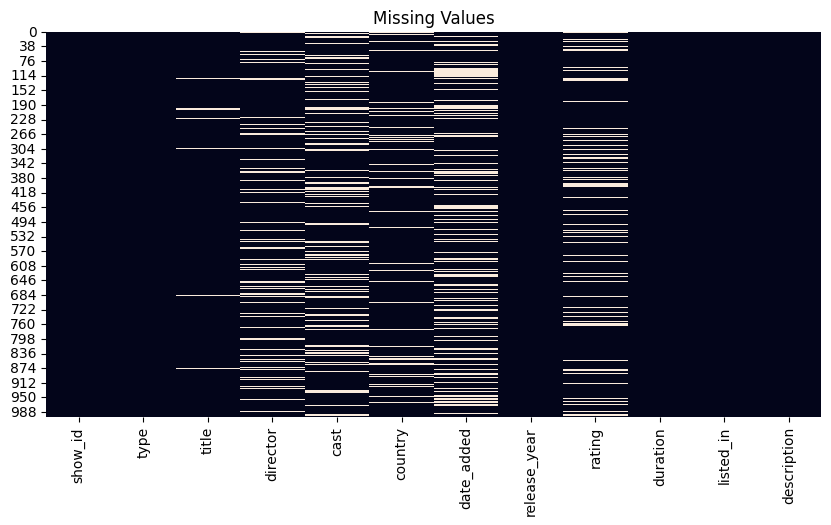

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

**Percentage of Missing Values**

In [ ]:
(df.isnull().sum()/len(df))*100

,0
show_id,0.0
type,0.0
title,1.4
director,15.2
cast,19.0
country,11.0
date_added,26.3
release_year,0.0
rating,17.0
duration,0.0


**Fill Missing Director**

In [ ]:
df['director']=df['director'].fillna("Unknown")

**Fill Missing Cast**

In [ ]:
df['cast']=df['cast'].fillna("Unknown")

**Fill Missing Country**

In [ ]:
df['country']=df['country'].fillna("Unknown")

**Fill Missing Rating**

In [ ]:
df['rating']=df['rating'].fillna(df['rating'].mode()[0])

**Remove Rows with Missing Title**

In [ ]:
df=df.dropna(subset=['title'])

**Check Missing Value Again**

In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,258
release_year,0
rating,0
duration,0


**Check Duplicate Records**

In [ ]:
df.duplicated().sum()

np.int64(0)

**Remove Duplicates**

In [ ]:
df=df.drop_duplicates()

**Verify Duplicates**

In [ ]:
df.duplicated().sum()

np.int64(0)

**Check Data Types**

In [ ]:
df.dtypes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


**Convert Date Column**

In [ ]:
df['date_added']=pd.to_datetime(df['date_added'],errors='coerce')

**Check Date Conversion**

In [ ]:
df['date_added'].head()

,date_added
0,2016-04-30
1,2020-02-25
2,2017-03-14
3,NaT
5,NaT


**Standardize Country Names**

In [ ]:
df['country']=df['country'].replace({
    "USA":"United States",
    "UK":"United Kingdom"
})

**Remove Extra Spaces**

In [ ]:
df['title']=df['title'].str.strip()

df['director']=df['director'].str.strip()

df['country']=df['country'].str.strip()

**Convert Column Names to Lowercase**

In [ ]:
df.columns=df.columns.str.lower()

**Replace Spaces in Column Names**

In [ ]:
df.columns=df.columns.str.replace(" ","_")

**Extract Duration Number**

In [ ]:
df['duration_num']=df['duration'].str.extract('(\d+)')

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_5502/3259723291.py:1: SyntaxWarning: invalid escape sequence '\d'
  df['duration_num']=df['duration'].str.extract('(\d+)')


**Convert Duration to Integer**

In [ ]:
df['duration_num']=pd.to_numeric(df['duration_num'])

**Check Outliers**

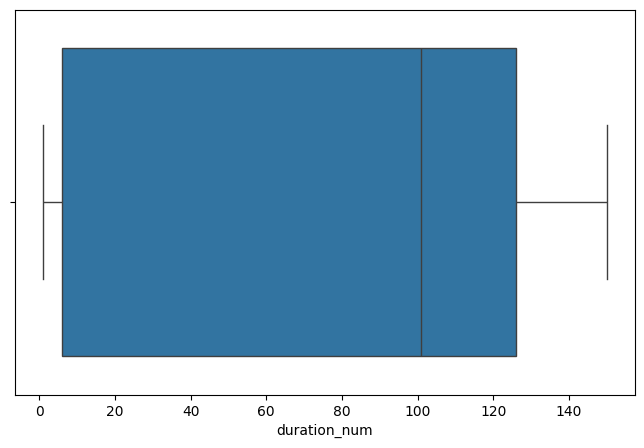

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['duration_num'])
plt.show()

**Histogram**

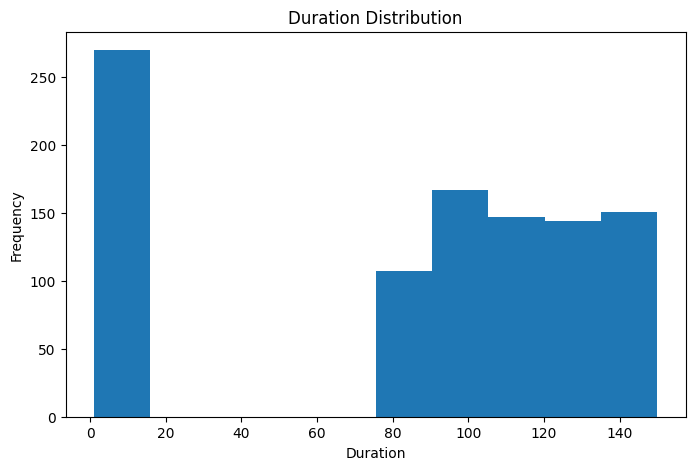

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['duration_num'])
plt.title("Duration Distribution")
plt.xlabel("Duration")
plt.ylabel("Frequency")
plt.show()

**Count Plot**

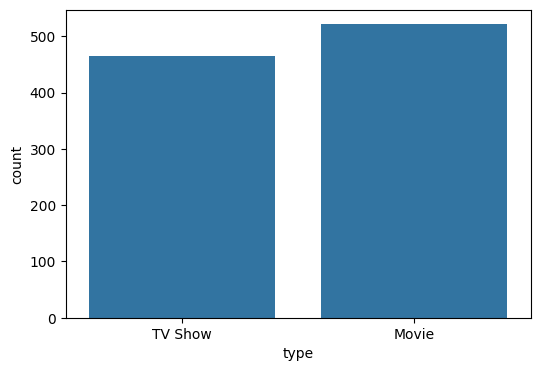

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='type',data=df)
plt.show()

**Movies vs TV Shows Pie Chart**

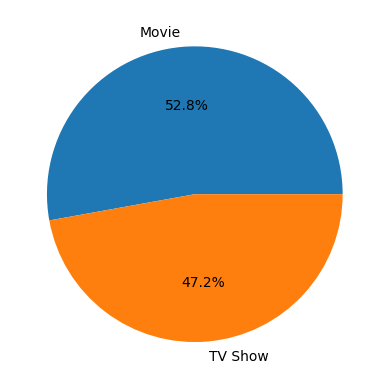

In [ ]:
df['type'].value_counts().plot(kind='pie',autopct='%1.1f%%')
plt.ylabel("")
plt.show()

**Top Countries**

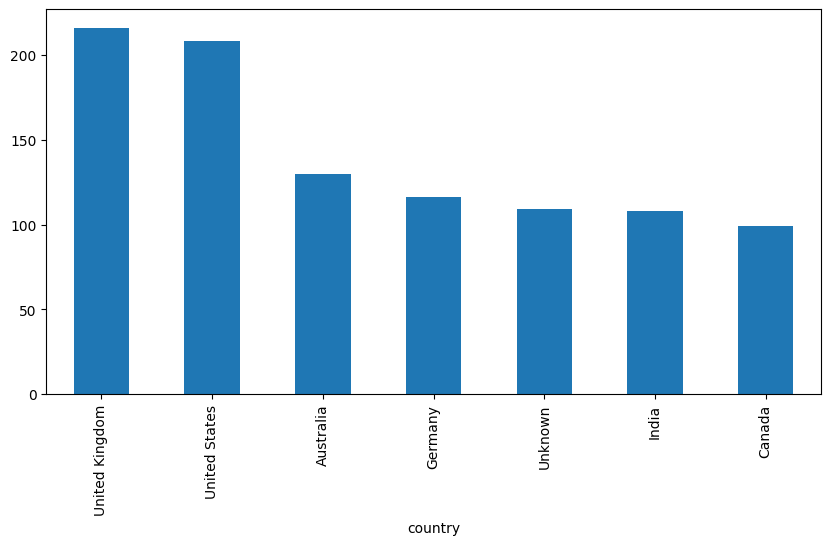

In [ ]:
plt.figure(figsize=(10,5))
df['country'].value_counts().head(10).plot(kind='bar')
plt.show()

**Top Genres**

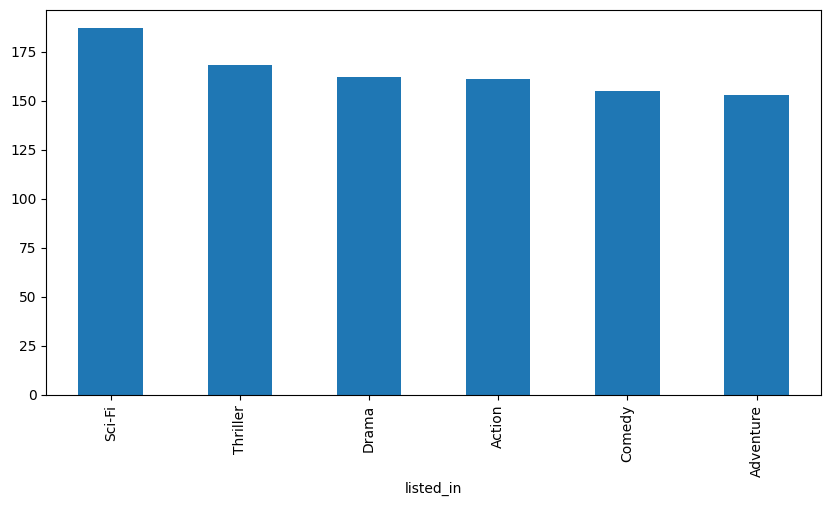

In [ ]:
plt.figure(figsize=(10,5))
df['listed_in'].value_counts().head(10).plot(kind='bar')
plt.show()

**Correlation Matrix**

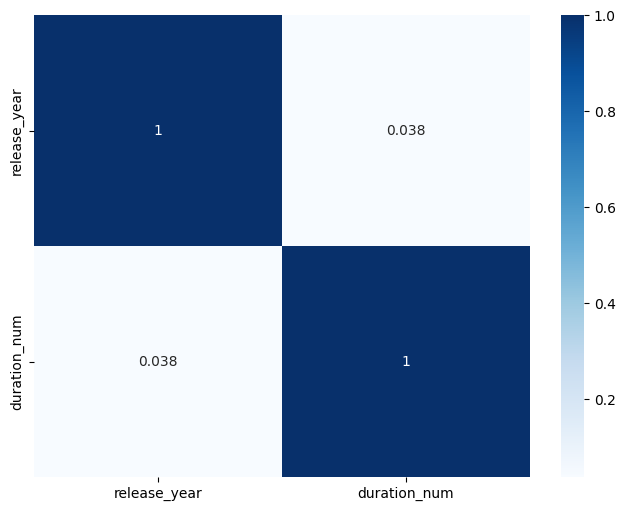

In [ ]:
numeric_df=df.select_dtypes(include='number')

plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(),annot=True,cmap='Blues')
plt.show()

**Final Dataset Information**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 986 entries, 0 to 999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       986 non-null    object        
 1   type          986 non-null    object        
 2   title         986 non-null    object        
 3   director      986 non-null    object        
 4   cast          986 non-null    object        
 5   country       986 non-null    object        
 6   date_added    252 non-null    datetime64[ns]
 7   release_year  986 non-null    int64         
 8   rating        986 non-null    object        
 9   duration      986 non-null    object        
 10  listed_in     986 non-null    object        
 11  description   986 non-null    object        
 12  duration_num  986 non-null    int64         
dtypes: datetime64[ns](1), int64(2), object(10)
memory usage: 107.8+ KB


**Final Missing Values**

In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,734
release_year,0
rating,0
duration,0


**Save Clean Dataset**

In [ ]:
df.to_excel("Netflix_Cleaned_Dataset.xlsx",index=False)

**Download Clean Dataset**

In [ ]:
from google.colab import files

files.download("Netflix_Cleaned_Dataset.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>